#  Predictive Analytics & Machine Learning

R² Score: 0.2063
Mean Absolute Error (MAE): 14.50


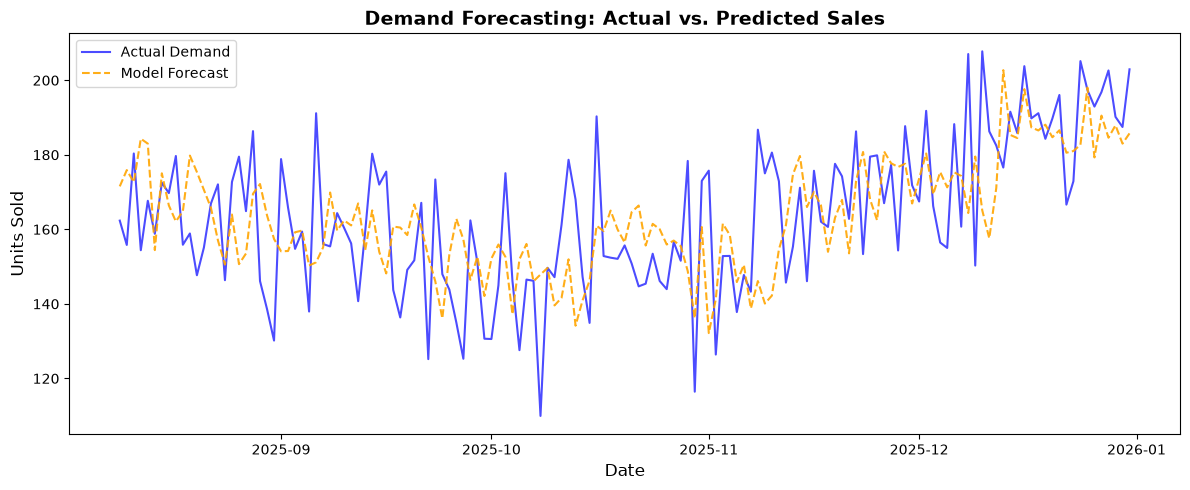

In [1]:
## Building a regression models for sales and demand forecasting

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Create a simulated daily sales dataset with a time index
np.random.seed(42)
date_rng = pd.date_range(start='2024-01-01', end='2025-12-31', freq='D')
df_time = pd.DataFrame({'Date': date_rng})

# Simulate baseline demand with weekly seasonality and noise
df_time['Base_Demand'] = 200 + 50 * np.sin(df_time['Date'].dt.dayofyear * (2 * np.pi / 365))
df_time['Sales'] = df_time['Base_Demand'] + np.random.normal(0, 15, len(df_time))

# 2. Feature Engineering: Create Lag Features and Rolling Averages
# Lag 1 (Sales yesterday), Lag 7 (Sales same day last week)
df_time['Sales_Lag_1'] = df_time['Sales'].shift(1)
df_time['Sales_Lag_7'] = df_time['Sales'].shift(7)

# 7-day rolling moving average to smooth out daily volatility
df_time['Sales_Rolling_Avg_7'] = df_time['Sales'].shift(1).rolling(window=7).mean()

# Drop rows with NaN values created by shifting/rolling
df_time = df_time.dropna()

# 3. Define Features (X) and Target (y)
features = ['Sales_Lag_1', 'Sales_Lag_7', 'Sales_Rolling_Avg_7']
X = df_time[features]
y = df_time['Sales']

# 4. Chronological Train-Test Split (Crucial for time series: train on past, test on future)
train_size = int(len(df_time) * 0.8)
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

# 5. Train Model & Evaluate
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_test, y_pred):.2f}")

# 6. Plot Actual vs. Predicted Sales
plt.figure(figsize=(12, 5))
plt.plot(df_time['Date'].iloc[train_size:], y_test, label='Actual Demand', color='blue', alpha=0.7)
plt.plot(df_time['Date'].iloc[train_size:], y_pred, label='Model Forecast', color='orange', linestyle='--', alpha=0.9)
plt.title('Demand Forecasting: Actual vs. Predicted Sales', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Units Sold', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

In [2]:
## Use classification models for customer churn prediction

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# 1. Load dataset
df = pd.read_csv(r"C:\Users\Admin\Downloads\churn-bigml-80.csv")

# 2. Ensure binary target exists
if 'Churn_binary' not in df.columns:
    if df['Churn'].dtype == 'object':
        df['Churn_binary'] = df['Churn'].map({'True': 1, 'False': 0, 'Yes': 1, 'No': 0, True: 1, False: 0})
    else:
        df['Churn_binary'] = df['Churn'].astype(int)

# 3. Select features and handle categorical variables
features = ['Account length', 'Customer service calls', 'Total day minutes', 'Total eve minutes', 'International plan']
X = pd.get_dummies(df[features], drop_first=True)
y = df['Churn_binary']

# 4. Train-test split with stratification to maintain class balance
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 5. Scale features (crucial for Logistic Regression distance/regularization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Initialize models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# 7. Train and evaluate each model
for name, model in models.items():
    print(f"================ {name} ================")
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]
        
    print(classification_report(y_test, y_pred))
    print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}\n")

================ Logistic Regression ================
              precision    recall  f1-score   support

           0       0.86      0.96      0.91       456
           1       0.33      0.12      0.17        78

    accuracy                           0.84       534
   macro avg       0.60      0.54      0.54       534
weighted avg       0.79      0.84      0.80       534

ROC-AUC Score: 0.7619

================ Random Forest ================
              precision    recall  f1-score   support

           0       0.93      0.96      0.94       456
           1       0.68      0.55      0.61        78

    accuracy                           0.90       534
   macro avg       0.80      0.75      0.78       534
weighted avg       0.89      0.90      0.89       534

ROC-AUC Score: 0.8329

================ Gradient Boosting ================
              precision    recall  f1-score   support

           0       0.91      0.96      0.94       456
           1       0.68      0.46    

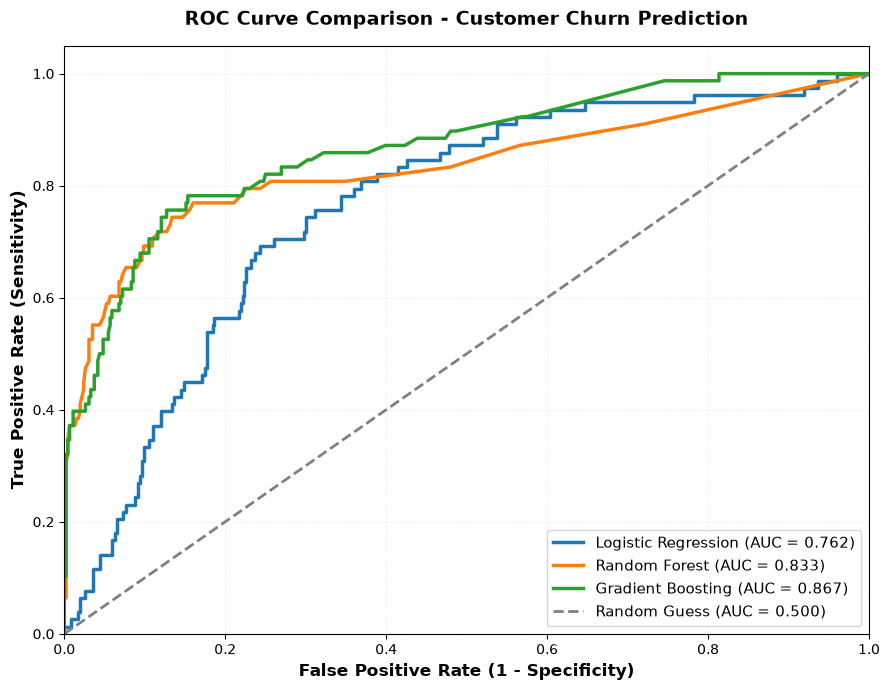

In [3]:


import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import auc, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load dataset and ensure binary target exists
df = pd.read_csv(r"C:\Users\Admin\Downloads\churn-bigml-80.csv")
if "Churn_binary" not in df.columns:
  if df["Churn"].dtype == "object":
    df["Churn_binary"] = df["Churn"].map({
        "True": 1,
        "False": 0,
        "Yes": 1,
        "No": 0,
        True: 1,
        False: 0,
    })
  else:
    df["Churn_binary"] = df["Churn"].astype(int)

# 2. Select features and split data
features = [
    "Account length",
    "Customer service calls",
    "Total day minutes",
    "Total eve minutes",
    "International plan",
]
X = pd.get_dummies(df[features], drop_first=True)
y = df["Churn_binary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale data for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Train models
lr_model = LogisticRegression(random_state=42).fit(X_train_scaled, y_train)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42).fit(
    X_train, y_train
)
gb_model = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)

# 4. Obtain predicted probabilities for the positive class
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]
rf_prob = rf_model.predict_proba(X_test)[:, 1]
gb_prob = gb_model.predict_proba(X_test)[:, 1]

# Store models and their probability outputs in a dictionary
models_probs = {
    "Logistic Regression": lr_prob,
    "Random Forest": rf_prob,
    "Gradient Boosting": gb_prob,
}

# 5. Plot Overlapping ROC Curves
plt.figure(figsize=(9, 7))

for name, prob in models_probs.items():
  fpr, tpr, thresholds = roc_curve(y_test, prob)
  roc_auc = auc(fpr, tpr)
  plt.plot(
      fpr, tpr, linewidth=2.5, label=f"{name} (AUC = {roc_auc:.3f})"
  )

# Plot diagonal reference line for random guessing (AUC = 0.500)
plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    linewidth=2,
    label="Random Guess (AUC = 0.500)",
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12, fontweight='bold')
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=12, fontweight='bold')
plt.title(
    "ROC Curve Comparison - Customer Churn Prediction",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.legend(loc="lower right", fontsize=11, frameon=True)
plt.grid(alpha=0.3, linestyle=":")
plt.tight_layout()

# Save figure for your GitHub README repository
plt.savefig("churn_roc_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

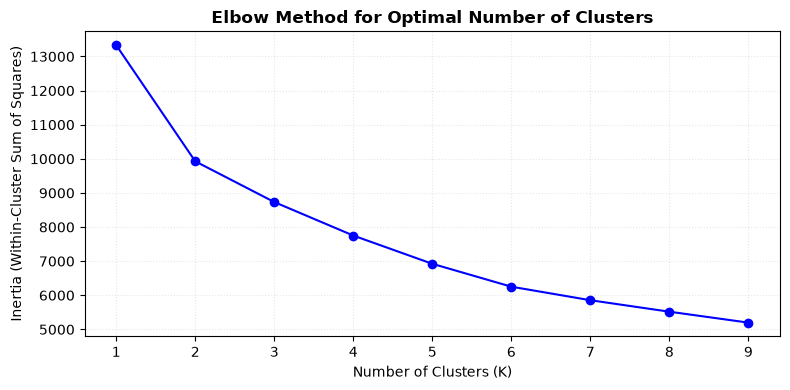

--- Customer Segment Profiles (Means) ---
                  Account length  Customer service calls  Total day minutes  \
Customer_Segment                                                              
0                      94.739425                3.269036         179.635364   
1                     101.628788                1.094697         132.041098   
2                     102.986261                1.057900         228.555545   

                  Total day charge  Total eve minutes  
Customer_Segment                                       
0                        30.538477         196.788494  
1                        22.447595         202.230492  
2                        38.854926         200.561433  

--- Churn Rate by Segment ---
Customer_Segment
0    21.32%
1     5.59%
2    19.92%
Name: Churn_binary, dtype: str


In [4]:
## Apply clustering for market segmentation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load dataset
df = pd.read_csv(r"C:\Users\Admin\Downloads\churn-bigml-80.csv")

# 2. Select behavioral features for segmentation
features = ['Account length', 'Customer service calls', 'Total day minutes', 'Total day charge', 'Total eve minutes']
X = df[features]

# 3. Scale features (Critical: K-Means relies on Euclidean distance, so features must be on the same scale)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Elbow Method to find the optimal number of clusters (K)
inertia = []
K_range = range(1, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.title('Elbow Method for Optimal Number of Clusters', fontsize=12, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=10)
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=10)
plt.grid(alpha=0.3, linestyle=':')
plt.tight_layout()
plt.show()

# 5. Fit Final K-Means Model (e.g., K = 3 distinct customer segments)
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Customer_Segment'] = kmeans_final.fit_predict(X_scaled)

# 6. Profile the Segments (Calculate mean values for each cluster)
segment_summary = df.groupby('Customer_Segment')[features].mean()
print("--- Customer Segment Profiles (Means) ---")
print(segment_summary)

# Calculate segment sizes and churn rates per segment
if 'Churn' in df.columns:
    df['Churn_binary'] = df['Churn'].map({'True': 1, 'False': 0, 'Yes': 1, 'No': 0, True: 1, False: 0})
    print("\n--- Churn Rate by Segment ---")
    print(df.groupby('Customer_Segment')['Churn_binary'].mean().map('{:.2%}'.format))

In [5]:
import pandas as pd
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# --- STEP 1: Train and Save the Model ---
df = pd.read_csv(r"C:\Users\Admin\Downloads\churn-bigml-80.csv")

# Ensure binary target exists
if 'Churn_binary' not in df.columns:
    df['Churn_binary'] = df['Churn'].map({'True': 1, 'False': 0, 'Yes': 1, 'No': 0, True: 1, False: 0})

features = ['Account length', 'Customer service calls', 'Total day minutes', 'Total eve minutes', 'International plan']
X = pd.get_dummies(df[features], drop_first=True)
y = df['Churn_binary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Serialize and save model to disk
joblib.dump(model, 'churn_rf_model.pkl')
print("Model successfully trained and saved as 'churn_rf_model.pkl'")


# --- STEP 2: Batch Scoring Pipeline (Simulating a fresh weekly data pull) ---
# Load the saved model later or in a separate production script
loaded_model = joblib.load('churn_rf_model.pkl')

# Imagine 'df_new_week' is fresh operational data pulled from your company database
df_new_week = df.copy() 
X_new = pd.get_dummies(df_new_week[features], drop_first=True)

# Generate churn probabilities (risk scores from 0.0 to 1.0)
df_new_week['Predicted_Churn_Probability'] = loaded_model.predict_proba(X_new)[:, 1]

# Assign risk tiers for business action
df_new_week['Risk_Tier'] = pd.cut(
    df_new_week['Predicted_Churn_Probability'],
    bins=[-0.1, 0.3, 0.7, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

# Export scored dataset for Power BI or stakeholder reporting
output_path = 'churn_scored_export.csv'
df_new_week[['Account length', 'Customer service calls', 'Predicted_Churn_Probability', 'Risk_Tier']].to_csv(output_path, index=False)
print(f"Batch scoring complete! Exported scored data to {output_path}")

Model successfully trained and saved as 'churn_rf_model.pkl'
Batch scoring complete! Exported scored data to churn_scored_export.csv


--- Monte Carlo Simulation Results (10,000 Runs) ---
Expected Mean ARR: $5,820,310.82
95% Confidence Interval for ARR: [$5,463,640.39, $6,177,387.72]
Probability of missing $6.0M ARR target: 83.90%


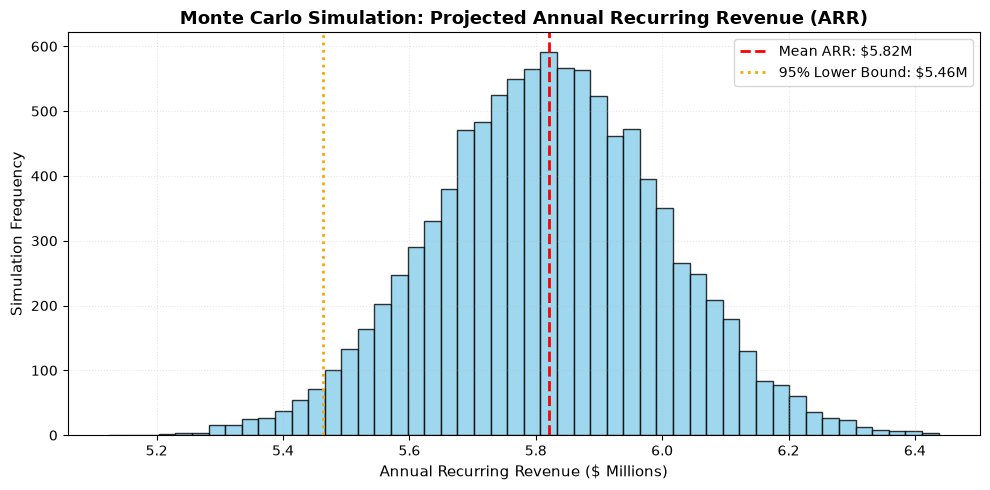

In [1]:
## Deploy machine learning models in business processes

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Set seed for reproducibility
np.random.seed(42)

# 2. Define baseline business parameters
n_simulations = 10000
base_customers = 10000
arpu = 50  # Average Revenue Per User ($ per month)

# 3. Simulate uncertain variables using probability distributions
# Churn Rate: Normally distributed around 15% (0.15) with a 3% standard deviation
simulated_churn_rates = np.random.normal(loc=0.15, scale=0.03, size=n_simulations)
simulated_churn_rates = np.clip(simulated_churn_rates, 0.05, 0.35) # Realistic bounds

# New Customer Acquisitions: Modeled using a Poisson distribution (average 1,200 new sign-ups)
simulated_acquisitions = np.random.poisson(lam=1200, size=n_simulations)

# 4. Calculate ending customers and Annual Recurring Revenue (ARR) for each simulation
ending_customers = base_customers * (1 - simulated_churn_rates) + simulated_acquisitions
annual_revenue = ending_customers * arpu * 12

# 5. Statistical Risk Analysis of Simulation Results
mean_arr = np.mean(annual_revenue)
ci_lower = np.percentile(annual_revenue, 2.5)   # 2.5th percentile (Downside risk)
ci_upper = np.percentile(annual_revenue, 97.5)  # 97.5th percentile (Upside potential)
prob_target_miss = np.mean(annual_revenue < 6000000) # Probability ARR falls below $6.0M

print(f"--- Monte Carlo Simulation Results ({n_simulations:,} Runs) ---")
print(f"Expected Mean ARR: ${mean_arr:,.2f}")
print(f"95% Confidence Interval for ARR: [${ci_lower:,.2f}, ${ci_upper:,.2f}]")
print(f"Probability of missing $6.0M ARR target: {prob_target_miss:.2%}")

# 6. Plotting the Risk Distribution for your Portfolio README
plt.figure(figsize=(10, 5))
plt.hist(annual_revenue / 1e6, bins=50, color='skyblue', edgecolor='black', alpha=0.8)
plt.axvline(mean_arr / 1e6, color='red', linestyle='--', linewidth=2, label=f'Mean ARR: ${mean_arr/1e6:.2f}M')
plt.axvline(ci_lower / 1e6, color='orange', linestyle=':', linewidth=2, label=f'95% Lower Bound: ${ci_lower/1e6:.2f}M')
plt.title('Monte Carlo Simulation: Projected Annual Recurring Revenue (ARR)', fontsize=13, fontweight='bold')
plt.xlabel('Annual Recurring Revenue ($ Millions)', fontsize=11)
plt.ylabel('Simulation Frequency', fontsize=11)
plt.legend(loc='upper right')
plt.grid(alpha=0.3, linestyle=':')
plt.tight_layout()
plt.show()

In [ ]:
# Develop simulation models for business decisions
import numpy as np
import pandas as pd
impoprt matplotlib.pyplot as plt

# 1. Set seed for reproducibility
np.random.seed(42)

# 2. Defining baseline business parameters
n_simulations = 10000
base_customers = 10000
arpu = 50 # Average Revenue Per User ($ per month)

# 3. Simulate uncertain variables using probability distributions
# Churn Rate:| Normally diistributed around 15% (0,15) with a 3% stardard deviation
simulated_churn_rates = np.random.normal(loc=0.15, scale=0.03, size=n_simulatiions)
simulated_churn_rates = np.clip(simulated_curn_rates, 0.05, 0.35) #Realistic bounds

# New Customer Acqusitions: Modeled using a Poisson distribution ( average 1,200 new signups)
simulateed_acquisitions = np.random.poisson(lam=1200, size=n_simulations)

# 4.Calculate ending customers and AAnnual Recurring Revenue (ARR) for each simulations
ending_customers = base_customers * (1 - simulated_churn_rates) + simulated_acquisitions
annual_revenue = ending_customers * arpu * 12

# 5. Statistical Risk Analysis of Simulation Results
mean_arr = np.mean(annual_revenue)
ci_lower = np.percentile(annual_revenue, 2.5) # 2.5th percentle (Downside risk)
ci_upper = np.percentile(annual_revenue, 97.5) # 97.5th percentile (Upside potential)
prob_target_miss = np.mean(annual_revenue < 6000000) # Probability ARR falls below $6.0M

print(f"--- Monte Carlo Simulation Results ({n_simulations:,} Runs) ---")
print(f"Expected Mean ARR: ${mean_arr:,.2f}")
print(f"95% Confidence Interval for ARR; [${ci_lower;,.2f}, ${ci_upper:,.2f}]")
print(f"Probability of missing $6.0M ARR target: {prob_target_miss:.2%}")

# 6. Plotting the Risk Distribution for my Porfolio README
plt.figure(figsize=(10, 5))
plt.hist(annual_revenue / 1e6, bins=50, color='skyblue', edgecolor='black', alpha=0.8)
plt.axvline(mean_arr / 1e6, color='red', linestyle='--',linewidth=2, label=f'Mean ARR: ${mean_arr/1e6.2f}M')
plt.axvline(ci_lower / 1e6, color='orange', linestyle=':', linewidth=2, label=f'95% Lower Bounds:${ci_lower/1e6:.2f}M)
plt.title('Monte Carlo Simulation: Projected Annual Recurring Revenue 9ARR)', fontsize=13, fontwight='bold')
plt.xlabel('Annual Recurring Revenue ($ Millions)', fontsize=11)
plt.ylabel('Simulation Frequency', fontsize=11)
plt.grid9alpha=0.3, linestyle=':')
plt.tight_layout()
plt.show()